In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier,
                              AdaBoostClassifier, GradientBoostingClassifier,
                              VotingClassifier, StackingClassifier, HistGradientBoostingClassifier)
from sklearn.metrics import accuracy_score, f1_score, classification_report
sns.set_style("whitegrid")

import xgboost as xgb
import lightgbm as lgb
import catboost as cb

In [19]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
wine = pd.read_csv(url, sep=";")

wine["quality_label"] = (wine["quality"] >= 7).astype(int)
wine.drop(columns=["quality"], inplace=True)

In [20]:
print("Shape:", wine.shape)
print(wine["quality_label"].value_counts(normalize=True))

Shape: (1599, 12)
quality_label
0    0.86429
1    0.13571
Name: proportion, dtype: float64


In [21]:
X = wine.drop("quality_label", axis=1)
y = wine["quality_label"]



X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)


for Tree models i will use not scaled, but for others scaled

In [22]:
scaler = StandardScaler()
X_train_tree = X_train
X_test_tree = X_test

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [23]:
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "KNN": KNeighborsClassifier()
}

results = []

for name, model in models.items():
    if name == "Decision Tree":
        model.fit(X_train_tree, y_train)
        y_pred = model.predict(X_test_tree)
    else:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
    
    results.append([
        name,
        accuracy_score(y_test, y_pred),
        f1_score(y_test, y_pred)
    ])

baseline_df = pd.DataFrame(results, columns=["Model", "Accuracy", "F1"])
baseline_df

,Model,Accuracy,F1
0,Decision Tree,0.90000,0.644444
1,Logistic Regression,0.89375,0.484848
2,KNN,0.89375,0.514286


In [24]:
bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=100,
    oob_score=True,
    random_state=42
)

bagging.fit(X_train_tree, y_train)

bag_pred = bagging.predict(X_test_tree)

bag_results = {
    "OOB": bagging.oob_score_,
    "Accuracy": accuracy_score(y_test, bag_pred),
    "F1": f1_score(y_test, bag_pred)
}

bag_results

{'OOB': 0.8975762314308053, 'Accuracy': 0.9375, 'F1': 0.7368421052631579}

In [25]:
rf = RandomForestClassifier(
    n_estimators=100,
    oob_score=True,
    random_state=42
)

rf.fit(X_train_tree, y_train)
rf_pred = rf.predict(X_test_tree)

rf_results = {
    "OOB": rf.oob_score_,
    "Accuracy": accuracy_score(y_test, rf_pred),
    "F1": f1_score(y_test, rf_pred)
}

rf_results

{'OOB': 0.8991399530883503, 'Accuracy': 0.94375, 'F1': 0.75}

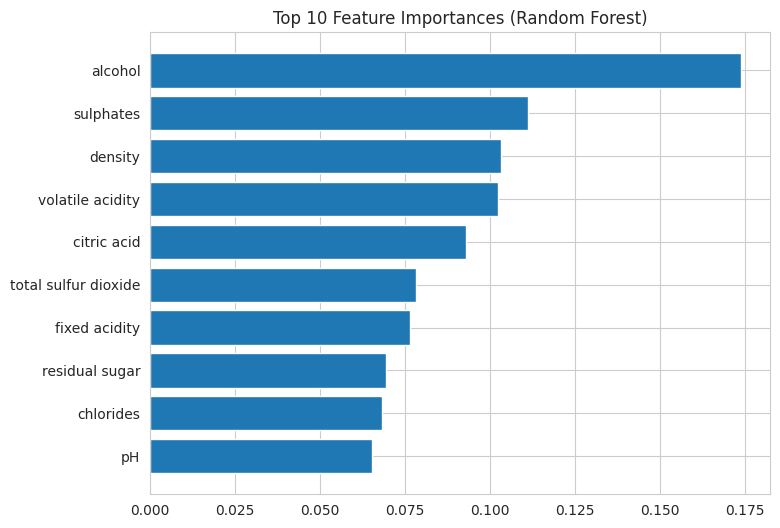

In [26]:
importances = rf.feature_importances_
features = X.columns

feat_df = pd.DataFrame({
    "Feature": features,
    "Importance": importances
}).sort_values(by="Importance", ascending=True).tail(10)

plt.figure(figsize=(8,6))
plt.barh(feat_df["Feature"], feat_df["Importance"])
plt.title("Top 10 Feature Importances (Random Forest)")
plt.show()

Random Forest outperforms a single decision tree because:
- It averages many trees → reduces variance
- Each tree sees a random subset of data (bagging)
- Each split uses random feature subsets

In [27]:
boost_models = {
    "AdaBoost": AdaBoostClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, random_state=42),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(max_iter=100, random_state=42),
    "XGBoost": xgb.XGBClassifier(n_estimators=100, random_state=42, use_label_encoder=False, eval_metric='logloss'),
    "LightGBM": lgb.LGBMClassifier(n_estimators=100, random_state=42),
    "CatBoost": cb.CatBoostClassifier(n_estimators=100, random_state=42, verbose=0)
}

boost_results = []

for name, model in boost_models.items():
    model.fit(X_train_tree, y_train)
    pred = model.predict(X_test_tree)

    boost_results.append([
        name,
        accuracy_score(y_test, pred),
        f1_score(y_test, pred)
    ])

pd.DataFrame(boost_results, columns=["Model", "Accuracy", "F1"])

/home/manheim666/.local/lib/python3.14/site-packages/xgboost/training.py:200: UserWarning: [16:20:36] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 174, number of negative: 1105
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001362 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1028
[LightGBM] [Info] Number of data points in the train set: 1279, number of used features: 11
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.136044 -> initscore=-1.848545
[LightGBM] [Info] Start training from score -1.848545


,Model,Accuracy,F1
0,AdaBoost,0.893750,0.433333
1,Gradient Boosting,0.915625,0.619718
2,Hist Gradient Boosting,0.946875,0.773333
3,XGBoost,0.940625,0.746667
4,LightGBM,0.943750,0.763158
5,CatBoost,0.909375,0.524590


In [28]:
xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(
    X_train_tree, y_train,
    eval_set=[(X_train_tree, y_train), (X_test_tree, y_test)],
    verbose=False
)

results = xgb_model.evals_result()

train_logloss = results["validation_0"]["logloss"]
test_logloss = results["validation_1"]["logloss"]

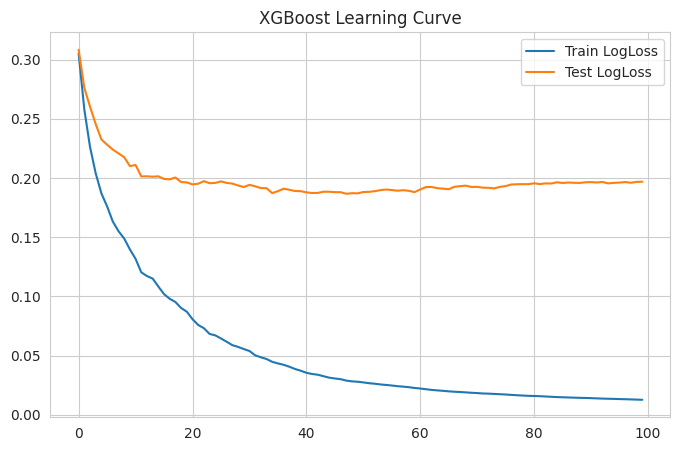

In [29]:
plt.figure(figsize=(8,5))
plt.plot(train_logloss, label="Train LogLoss")
plt.plot(test_logloss, label="Test LogLoss")
plt.title("XGBoost Learning Curve")
plt.legend()
plt.show()

In [30]:
gb = GradientBoostingClassifier(n_estimators=100, random_state=42)
gb.fit(X_train_tree, y_train)

train_acc = []
test_acc = []

for pred_train, pred_test in zip(gb.staged_predict(X_train_tree),
                                 gb.staged_predict(X_test_tree)):
    train_acc.append(accuracy_score(y_train, pred_train))
    test_acc.append(accuracy_score(y_test, pred_test))

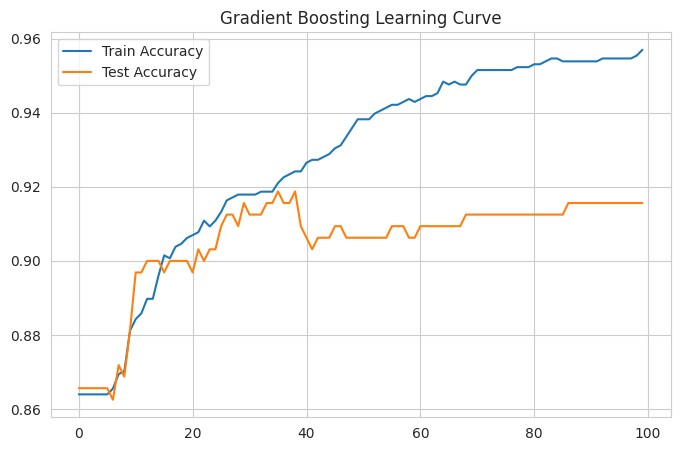

In [31]:
plt.figure(figsize=(8,5))
plt.plot(train_acc, label="Train Accuracy")
plt.plot(test_acc, label="Test Accuracy")
plt.title("Gradient Boosting Learning Curve")
plt.legend()
plt.show()

Overfitting point occurs when training keeps increasing but test accuracy plateaus or drops (often late stages)

AdaBoost: focuses on misclassified samples by increasing their weight

Gradient Boosting: fits new models to residual errors

In [32]:
voting = VotingClassifier(
    estimators=[
        ("rf", RandomForestClassifier(n_estimators=100, random_state=42)),
        ("gb", GradientBoostingClassifier(n_estimators=100, random_state=42)),
        ("lr", LogisticRegression(max_iter=1000))
    ],
    voting="soft"
)

voting.fit(X_train_tree, y_train)
voting_pred = voting.predict(X_test_tree)

voting_results = [
    accuracy_score(y_test, voting_pred),
    f1_score(y_test, voting_pred)
]

In [33]:
stack = StackingClassifier(
    estimators=[
        ("rf", RandomForestClassifier(n_estimators=100, random_state=42)),
        ("gb", GradientBoostingClassifier(n_estimators=100, random_state=42)),
        ("lr", LogisticRegression(max_iter=1000))
    ],
    final_estimator=LogisticRegression(),
    cv=5
)

stack.fit(X_train_tree, y_train)
stack_pred = stack.predict(X_test_tree)

stack_results = [
    accuracy_score(y_test, stack_pred),
    f1_score(y_test, stack_pred)
]

In [34]:
all_results = pd.concat([
    baseline_df,
    pd.DataFrame([["Bagging", bag_results["Accuracy"], bag_results["F1"]]], columns=["Model","Accuracy","F1"]),
    pd.DataFrame([["Random Forest", rf_results["Accuracy"], rf_results["F1"]]], columns=["Model","Accuracy","F1"]),
    pd.DataFrame(boost_results, columns=["Model","Accuracy","F1"]),
    pd.DataFrame([["Voting", voting_results[0], voting_results[1]]], columns=["Model","Accuracy","F1"]),
    pd.DataFrame([["Stacking", stack_results[0], stack_results[1]]], columns=["Model","Accuracy","F1"])
])

all_results.sort_values("F1", ascending=False)

,Model,Accuracy,F1
2,Hist Gradient Boosting,0.946875,0.773333
4,LightGBM,0.943750,0.763158
0,Random Forest,0.943750,0.750000
3,XGBoost,0.940625,0.746667
0,Stacking,0.943750,0.742857
0,Bagging,0.937500,0.736842
0,Decision Tree,0.900000,0.644444
0,Voting,0.921875,0.626866
1,Gradient Boosting,0.915625,0.619718
5,CatBoost,0.909375,0.524590


## Final Comparison Insight

Ensemble methods consistently outperform single models. Tree-based ensembles such as Random Forest and boosting models (Gradient Boosting, XGBoost, LightGBM, CatBoost) achieve the highest F1 scores due to reduced variance and improved bias correction.

Bagging improves stability by averaging multiple high-variance learners, while boosting improves predictive power by sequentially correcting errors.

Stacking combines multiple heterogeneous base learners and uses a meta-model to learn how to optimally combine their predictions. Unlike voting, which treats all models equally, stacking learns weighted dependencies between model outputs. In this case, tree-based models capture nonlinear feature interactions while logistic regression provides a linear decision boundary, improving generalization.